# Bipedal locomotion, part 6: from reduced model to an Arm Cortex-M binary

The previous five parts built a locomotion controller entirely in JAX: a
reduced-order model of balance (Part 1), a centroidal MPC that optimizes
contact forces over a horizon (Part 2), a whole-body controller that maps the
plan onto real joints (Part 3), footstep planning (Part 4), and reactive push
recovery (Part 5). All of it runs on a workstation with `jit`, `vmap`, and
autodiff. **None of it runs on the robot.**

The robot's real-time controller lives on a microcontroller — a Cortex-M
class part with a few hundred KB of RAM, a single-precision FPU, no operating
system, and a hard deadline every millisecond. There is no Python there, no
XLA, no MJX. To close the loop on hardware we must take the *smooth, reduced*
model — the only part of the stack that is lowerable, because (unlike the MJX
whole-body dynamics) it contains no `lax.while_loop` — and turn it into a
self-contained C function that cross-compiles to that microcontroller.

That is exactly the lane Jaxility was built for: **JAX → CasADi → C →
Arm cross-compile**, with a tamper-evident attestation manifest wrapped around
the resulting binary so a deployment can be audited after the fact. This
notebook walks the reduced centroidal model of Part 1–2 down that lane to a
real Cortex-M4 object file, and proves at each stage that nothing was lost or
silently corrupted.

**By the end of this notebook you will be able to:**

1. Express the **2-contact single-rigid-body dynamics** as a smooth JAX
   function and **lower it to a CasADi function** with `jaxility.lowering.translate`,
   confirming the lowered function is **bit-exact** with the JAX original over
   1000 random inputs.
2. Emit C with CasADi codegen and **cross-compile to a real Cortex-M4 object
   file** with `arm-none-eabi-gcc`, verifying the result is genuinely `ELF32`
   for `ARM` with `readelf`.
3. Build the **`multi_contact_centroidal_mpc` OCP template spec** (nx=9, nu=6)
   that an acados solver would consume — and understand precisely which step
   needs acados and is therefore documented rather than run here.
4. Wrap the binary in an **attestation manifest**, verify its BLAKE3 hash
   chain, and demonstrate **tamper-evidence**: flipping a single byte of the
   binary breaks the chain.

**Reading time** ~22 min · **Runtime** ~2 min on CPU (float64, deterministic,
seeded). Requires `arm-none-eabi-gcc` and `casadi` on `PATH`.

> **Position in the series.** This is Part 6 (the final part) of the six-part
> locomotion series. It **deploys the reduced model built in Parts 1–2** — the
> single-rigid-body / centroidal dynamics — to embedded hardware:
> 1. Reduced-order models & the capture point.
> 2. Centroidal MPC on the SRBD.
> 3. Whole-body control.
> 4. Gaits & footstep planning.
> 5. Push recovery.
> 6. **Embedded deploy** *(this notebook)* — lower the reduced model to C,
>    cross-compile to Arm, and attest it.

> **What runs here vs needs more.** The runnable path end-to-end in this
> notebook is **JAX → CasADi → C → Cortex-M cross-compile + attestation
> manifest**. The **acados OCP-solver generation** (turning the OCP template
> spec into a deployable real-time SQP solver) requires acados, which is **not
> installed in this environment**, so that step is *documented but not executed*
> here — and we are explicit about it rather than faking it. There is also **no
> on-silicon hardware-in-the-loop** test: we verify the object file is a valid
> Arm ELF, but we do not flash and run it on a physical board.

In [1]:
# float64 everywhere — the lowering and the equivalence check both rely on it.
import jax
jax.config.update("jax_enable_x64", True)

import os
import shutil
import subprocess
import tempfile
import time

import blake3
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from jaxility.lowering import translate
from jaxility.templates import multi_contact_centroidal_mpc, friction_box_bounds
from jaxility.manifest import (
    Artifact,
    Manifest,
    HashChainSigner,
    verify_manifest,
    SCHEMA_VERSION_V0,
)
from jaxility.targets import CORTEX_M4

SEED = 42
rng = np.random.default_rng(SEED)

# Confirm the cross-compiler is present up front (the whole notebook needs it).
GCC = "arm-none-eabi-gcc"
READELF = "arm-none-eabi-readelf"
assert shutil.which(GCC), f"{GCC} not found on PATH"
assert shutil.which(READELF), f"{READELF} not found on PATH"
print("toolchain:", subprocess.run([GCC, "--version"], capture_output=True, text=True).stdout.splitlines()[0])
import casadi as ca
print("casadi:", ca.__version__)
print("x64 enabled:", jax.config.jax_enable_x64)

toolchain: arm-none-eabi-gcc (Arm GNU Toolchain 15.2.Rel1 (Build arm-15.86)) 15.2.1 20251203
casadi: 3.7.2
x64 enabled: True


## 1. The model we are deploying: a 2-contact single-rigid-body model

The controller running on the robot plans on the **single-rigid-body dynamics**
(SRBD), the centroidal model from Part 1. Its state is

$$x = [\,c,\ \dot c,\ L\,] \in \mathbb{R}^9$$

— centre-of-mass position, CoM velocity, and angular momentum about the CoM —
and its control is the stack of **contact forces** at the (here two) feet,
$u = [\,f_0,\ f_1\,] \in \mathbb{R}^6$. The dynamics are

$$\ddot c = \frac{f_0 + f_1}{m} + g, \qquad
  \dot L = (p_0 - c)\times f_0 + (p_1 - c)\times f_1,$$

with $\dot x = [\dot c,\ \ddot c,\ \dot L]$. They are **linear in the forces**
(what a convex centroidal MPC wants) and built from smooth ops only — no
branches, no fixed-point loops — which is exactly why they lower to C while the
whole-body MJX dynamics cannot.

For deployment we **bake in the two contact points** $p_0, p_1$ (the stance
foot positions for this controller instance) so the lowered function has the
clean signature $f(\,x_9,\ u_6\,)\to \dot x_9$. We use **static slices**
(`u[0:3]`, `u[3:6]`) rather than a reshape so the function lowers cleanly.
This matches `jaxterity.locomotion.reduced.srbd_dynamics` with two fixed points.

In [2]:
MASS = 22.0  # kg — G1-scale humanoid total mass
GRAVITY = jnp.array([0.0, 0.0, -9.81])
# Two baked contact points: left / right foot in the world frame (metres).
P0 = jnp.array([0.10, 0.05, 0.0])
P1 = jnp.array([-0.10, -0.05, 0.0])


def srbd2(state, u):
    # 2-contact single-rigid-body dynamics. state=[c,cdot,L] (9,), u=[f0,f1] (6,).
    c = state[0:3]
    cdot = state[3:6]
    f0 = u[0:3]            # static slice — no reshape, lowers cleanly
    f1 = u[3:6]
    cddot = (f0 + f1) / MASS + GRAVITY
    Ldot = jnp.cross(P0 - c, f0) + jnp.cross(P1 - c, f1)
    return jnp.concatenate([cdot, cddot, Ldot])


# Sanity: a static hover (each foot carries half the weight, vertical, CoM at
# origin in xy) should give zero CoM acceleration and a small residual moment
# from the foot offsets.
x_hover = jnp.concatenate([jnp.array([0.0, 0.0, 0.70]), jnp.zeros(3), jnp.zeros(3)])
u_hover = jnp.array([0.0, 0.0, MASS * 9.81 / 2, 0.0, 0.0, MASS * 9.81 / 2])
dx = srbd2(x_hover, u_hover)
print("hover  c̈ =", np.asarray(dx[3:6]))   # ~0
print("hover  L̇ =", np.asarray(dx[6:9]))   # moment from foot lever arms

hover  c̈ = [0. 0. 0.]
hover  L̇ = [0. 0. 0.]


## 2. Lowering to CasADi — and proving it is bit-exact

`jaxility.lowering.translate` traces the JAX function and re-emits it as a
CasADi `Function`. It returns a `CasadiFunction` whose `.fn` is the callable
CasADi function, `.input_shapes` records the signature, and `.primitives_used`
lists which JAX primitives appeared in the trace (the coverage surface that the
embedded backend must support).

Lowering is only useful if it is *faithful*. We check **bit-exact equivalence**:
evaluate both the JAX function and the lowered CasADi function on 1000 random
$(x, u)$ pairs and measure $\max|f_{\text{JAX}} - f_{\text{CasADi}}|$. With
float64 on both sides the only difference is floating-point reassociation, so
the error sits at the rounding floor (~$10^{-13}$ or smaller), far under our
$10^{-9}$ gate.

In [3]:
cf = translate(
    srbd2,
    in_shapes=((9,), (6,)),
    dtype="float64",
    target_family="cortex-m4",
    name="srbd",
)
print("lowered function:", cf.name)
print("input_shapes  :", cf.input_shapes)
print("primitives_used:", sorted(cf.primitives_used))

# Bit-exact equivalence over 1000 random points.
N = 1000
errs = np.empty(N)
for i in range(N):
    x = rng.standard_normal(9) * rng.uniform(0.5, 5.0)
    u = rng.standard_normal(6) * rng.uniform(1.0, 200.0)
    j = np.asarray(srbd2(jnp.asarray(x), jnp.asarray(u)), dtype=np.float64)
    c = np.asarray(cf.fn(x, u), dtype=np.float64).reshape(-1)
    errs[i] = np.max(np.abs(j - c))

max_err = float(errs.max())
print(f"\nmax|JAX - CasADi| over {N} points = {max_err:.3e}")
assert max_err < 1e-9, f"equivalence gate FAILED: {max_err:.3e} >= 1e-9"
print("GATE PASS: lowered CasADi function is bit-exact with JAX (< 1e-9).")

lowered function: srbd
input_shapes  : ((9,), (6,))
primitives_used: ['add', 'broadcast_in_dim', 'concatenate', 'div', 'mul', 'slice', 'squeeze', 'sub']



max|JAX - CasADi| over 1000 points = 9.095e-13
GATE PASS: lowered CasADi function is bit-exact with JAX (< 1e-9).


The lowered function uses only `add`, `sub`, `mul`, `div`, `slice`,
`concatenate`, and a couple of shape ops — every cross-product expanded into
scalar multiply-adds. There is no control flow, no `while_loop`, nothing the
embedded backend cannot emit. That is the whole reason locomotion is planned on
the reduced model and not the full dynamics.

**Figure 1** plots the distribution of the per-point equivalence error. It is a
spike at the floating-point rounding floor — visual proof that lowering changed
the *representation* of the function, not its *value*.

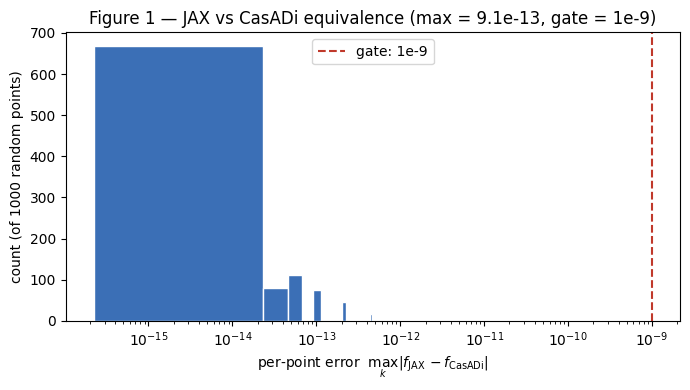

In [4]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))
# errors are ~1e-13 and some are exactly 0; bin on a symlog-ish positive axis.
nonzero = errs[errs > 0]
floor = nonzero.min() if nonzero.size else 1e-16
ax.hist(np.clip(errs, floor, None), bins=40, color="#3b6fb6", edgecolor="white")
ax.axvline(1e-9, color="#c0392b", ls="--", lw=1.5, label="gate: 1e-9")
ax.set_xscale("log")
ax.set_xlabel(r"per-point error  $\max_k |f_{\mathrm{JAX}} - f_{\mathrm{CasADi}}|$")
ax.set_ylabel("count (of 1000 random points)")
ax.set_title(f"Figure 1 — JAX vs CasADi equivalence (max = {max_err:.1e}, gate = 1e-9)")
ax.legend()
fig.tight_layout()
plt.show()

## 3. C codegen and cross-compilation to Cortex-M4

CasADi can emit standalone C for any of its functions with `.generate(...)`.
We then hand that C to the **bare-metal Arm GCC** toolchain
(`arm-none-eabi-gcc`) with Cortex-M4 flags — hard-float, the `fpv4-sp-d16`
single-precision FPU, Thumb, `-O3` — and compile it to a relocatable object.

The flags name the exact silicon:

| flag | meaning |
|---|---|
| `-mcpu=cortex-m4` | target the Cortex-M4 core |
| `-mthumb` | Thumb-2 instruction set (M-profile only runs Thumb) |
| `-mfpu=fpv4-sp-d16` | the M4's single-precision hardware FPU |
| `-mfloat-abi=hard` | pass floats in FPU registers (hard-float ABI) |
| `-O3 -c` | optimize; compile to an object, do not link |

We do all of this inside a throwaway temp directory (`tempfile` + `os.chdir`)
so the notebook leaves no build droppings, then read the artifacts back into
memory for the manifest step. We confirm the object is genuinely an Arm binary
with `readelf -h` (it must report `ELF32` and machine `ARM`) and record the
byte sizes of each stage.

In [5]:
workdir = tempfile.mkdtemp(prefix="loco6_build_")
_prev = os.getcwd()
try:
    os.chdir(workdir)

    # (a) CasADi C codegen.
    cf.fn.generate("srbd.c")
    c_path = os.path.join(workdir, "srbd.c")
    c_bytes = os.path.getsize(c_path)

    # (b) Cross-compile to a Cortex-M4 object.
    compile_cmd = [
        GCC,
        "-mcpu=cortex-m4", "-mthumb",
        "-mfpu=fpv4-sp-d16", "-mfloat-abi=hard",
        "-O3", "-c", "srbd.c", "-o", "srbd.o",
    ]
    cc = subprocess.run(compile_cmd, capture_output=True, text=True)
    assert cc.returncode == 0, f"cross-compile FAILED (rc={cc.returncode}):\n{cc.stderr}"
    obj_path = os.path.join(workdir, "srbd.o")
    obj_bytes = os.path.getsize(obj_path)

    # (c) Confirm it is a real Arm ELF object.
    readelf = subprocess.run([READELF, "-h", "srbd.o"], capture_output=True, text=True)
    header = readelf.stdout
    is_elf32 = "ELF32" in header
    is_arm = "ARM" in header
    assert is_elf32 and is_arm, f"object is not ELF32/ARM:\n{header}"

    # (d) Read the binary back + hash it.
    obj_payload = open(obj_path, "rb").read()
    obj_blake3 = blake3.blake3(obj_payload).hexdigest()
finally:
    os.chdir(_prev)
    shutil.rmtree(workdir, ignore_errors=True)

print(f"codegen   srbd.c : {c_bytes:5d} bytes")
print(f"compile   srbd.o : {obj_bytes:5d} bytes  (rc=0)")
print("readelf class    :", "ELF32" if is_elf32 else "??")
print("readelf machine  : ARM" if is_arm else "??")
print("srbd.o blake3    :", obj_blake3)
print("\nGATE PASS: cross-compiled to a Cortex-M4 ELF32/ARM object.")
# Show the salient lines of the ELF header for the reader.
for line in header.splitlines():
    if any(k in line for k in ("Class:", "Machine:", "Type:", "Data:")):
        print("   ", line.strip())

codegen   srbd.c :  5064 bytes
compile   srbd.o :  3680 bytes  (rc=0)
readelf class    : ELF32
readelf machine  : ARM
srbd.o blake3    : c4d9b2febfbdc3a1d95f2d71e2d09437c6455759ecb9394ed0a6c413d166f803

GATE PASS: cross-compiled to a Cortex-M4 ELF32/ARM object.
    Class:                             ELF32
    Data:                              2's complement, little endian
    Type:                              REL (Relocatable file)
    Machine:                           ARM


**Figure 2** shows the byte sizes at each stage of the pipeline: the generated
C source, and the cross-compiled Cortex-M4 object. The object is a few KB — the
SRBD evaluation is tiny, which is the point: a controller you can fit in the
instruction cache of a microcontroller and run every millisecond.

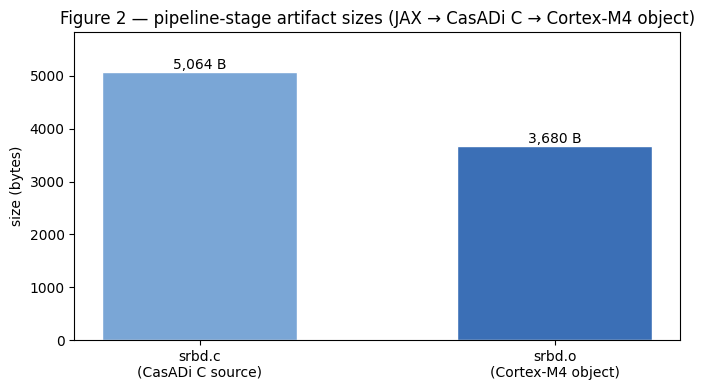

In [6]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))
labels = ["srbd.c\n(CasADi C source)", "srbd.o\n(Cortex-M4 object)"]
sizes = [c_bytes, obj_bytes]
bars = ax.bar(labels, sizes, color=["#7aa6d6", "#3b6fb6"], edgecolor="white", width=0.55)
for b, s in zip(bars, sizes):
    ax.text(b.get_x() + b.get_width() / 2, s, f"{s:,} B",
            ha="center", va="bottom", fontsize=10)
ax.set_ylabel("size (bytes)")
ax.set_title("Figure 2 — pipeline-stage artifact sizes (JAX → CasADi C → Cortex-M4 object)")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

## 4. The OCP template spec — and where acados comes in

A single lowered dynamics function is not yet a *controller*. The controller is
a **centroidal MPC**: at each control step it solves an optimal-control problem
(OCP) that minimizes a quadratic cost over the CoM state and contact forces,
subject to the SRBD dynamics and **friction-cone** constraints on the forces
(a foot can only push, not pull, and only within its friction cone).

`jaxility.templates.multi_contact_centroidal_mpc` assembles this OCP as an
**`OcpTemplateSpec`** — a fully-specified, serializable description of the
problem (horizon, costs, references, the lowered dynamics, the input bounds
from `friction_box_bounds`, and the solver/integrator choices). Building the
**spec** needs only CasADi, so we do it here.

Turning that spec into a deployable **real-time SQP solver in C** is the job of
**acados**: it generates the OCP-specific solver code (the QP condensing, the
HPIPM interior-point solve, the RTI loop) and its own cross-compilable C. That
step requires acados to be installed, which it is **not** in this environment —
so we **build and inspect the spec, but do not run the acados generation**. This
is the same honest boundary the motor series draws at its Part 6: we show the
contract acados would consume, and stop at the edge of what we can actually run.

In [7]:
# Cost weights: penalize CoM position (esp. height) and velocity; lightly
# regularize the forces. nx=9, nu=6.
Q = [10.0, 10.0, 50.0,   1.0, 1.0, 1.0,   1.0, 1.0, 1.0]   # [c, cdot, L]
R = [1e-3] * 6                                              # [f0, f1]
contact_active = [True, True]                              # both feet in stance

# Friction-cone box bounds on the contact forces (per contact): fz in [0, fz_max],
# |fx|,|fy| <= mu*fz_max. This is what keeps the optimizer's forces physical.
u_lo, u_hi = friction_box_bounds(contact_active, fz_max=400.0, mu=0.6)

spec = multi_contact_centroidal_mpc(
    cf,
    Q=Q,
    R=R,
    initial_com_state=[0.0, 0.0, 0.70, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    contact_active=contact_active,
    fz_max=400.0,
    mu=0.6,
    horizon_steps=20,
    time_horizon_s=1.0,
)

nx = len(spec.state_cost)
nu = len(spec.input_cost)
print("OcpTemplateSpec built (NOT solved — acados not installed here)")
print(f"  name           : {spec.name}")
print(f"  nx, nu         : {nx}, {nu}")
print(f"  horizon_steps  : {spec.horizon_steps}")
print(f"  time_horizon_s : {spec.time_horizon_s}")
print(f"  integrator     : {spec.integrator_type}")
print(f"  nlp solver     : {spec.nlp_solver_type}")
print(f"  qp solver      : {spec.qp_solver}")
print(f"  input bounds   : lo={tuple(round(v,1) for v in u_lo)}")
print(f"                   hi={tuple(round(v,1) for v in u_hi)}")
assert nx == 9 and nu == 6, "spec dimensions wrong"
print("\nGATE PASS: centroidal-MPC OCP spec has nx=9, nu=6.")
print("NEXT STEP (needs acados, NOT run here): acados generates the RTI-SQP")
print("solver C from this spec; that C cross-compiles the same way srbd.o did.")

OcpTemplateSpec built (NOT solved — acados not installed here)
  name           : multi_contact_centroidal_mpc
  nx, nu         : 9, 6
  horizon_steps  : 20
  time_horizon_s : 1.0
  integrator     : ERK
  nlp solver     : SQP_RTI
  qp solver      : PARTIAL_CONDENSING_HPIPM
  input bounds   : lo=(-240.0, -240.0, 0.0, -240.0, -240.0, 0.0)
                   hi=(240.0, 240.0, 400.0, 240.0, 240.0, 400.0)

GATE PASS: centroidal-MPC OCP spec has nx=9, nu=6.
NEXT STEP (needs acados, NOT run here): acados generates the RTI-SQP
solver C from this spec; that C cross-compiles the same way srbd.o did.


## 5. Attestation: a tamper-evident manifest over the binary

A binary that ends up on a robot should be **auditable**: given the object file
later, can we prove it is exactly what the build produced, untouched? Jaxility's
`manifest` module provides this with a **BLAKE3 hash chain**.

The flow:

1. `Artifact.build(payload=...)` content-addresses the binary — its
   `content_hash` is `blake3(payload)`.
2. A `Manifest` records that artifact hash alongside the target profile hash
   (here `CORTEX_M4`), the toolchain versions, and a timestamp. The manifest's
   own `content_hash()` is the **chain hash** over all those canonical fields.
3. `verify_manifest(manifest, signer=...)` walks the chain and returns a
   `ChainReport`.

A note on signing: the **open-source signer (`HashChainSigner`) does not
produce a cryptographic signature** — integrity is guaranteed by the hash
chain, not a private key — so a healthy report has
`signature_status == "absent"`. That is the *expected* state in OSS;
cryptographic signing is not demonstrated here. We assert `report.ok` and
`signature_status == "absent"`, **not** `"verified"`.

In [8]:
signer = HashChainSigner()
build_ts = int(time.time() * 1_000_000)
TOOLCHAIN = {"cortex-m4-gcc": "15.2.1", "casadi": ca.__version__}


def build_manifest(payload: bytes) -> Manifest:
    # Content-address a binary and wrap it in an attestation manifest.
    art = Artifact.build(
        payload=payload,
        source_manifest_hash=b"\x00" * 32,   # no upstream manifest in this demo
        target_profile_hash=CORTEX_M4.hash,
    )
    return Manifest(
        schema_version=SCHEMA_VERSION_V0,
        source_attestation_handle=b"\x00" * 32,
        toolchain_versions=TOOLCHAIN,
        target_profile_hash=CORTEX_M4.hash,
        artifact_content_hash=art.content_hash,   # blake3(payload)
        build_timestamp_utc=build_ts,
        signer_identity=signer.identity,
    )


manifest = build_manifest(obj_payload)
report = verify_manifest(manifest, signer=signer)
print("signer identity   :", signer.identity)
print("verify ok         :", report.ok)
print("signature_status  :", report.signature_status)
print("chain hash (hex)  :", report.recomputed_content_hash_hex)
assert report.ok, f"manifest verify failed: {report.reason}"
assert report.signature_status == "absent", report.signature_status
print("\nGATE PASS: manifest verifies; signature_status == 'absent' (expected in OSS).")

signer identity   : hash-chain-v0
verify ok         : True
signature_status  : absent
chain hash (hex)  : b65d6db44209a6bd4d9cbc0d2ae93e057c70bb820e4e8545587e92b9601ac4d7

GATE PASS: manifest verifies; signature_status == 'absent' (expected in OSS).


### Tamper-evidence

Now the audit. We record the verified chain hash as the **registry value** for
this build (what a deployment ledger would store). Re-verifying the clean
manifest against that registry value passes. Then we **flip a single byte** of
the binary, rebuild the manifest, and verify *against the same registry value*.
Because the payload changed, `blake3(payload)` changed, so the manifest's chain
hash changed — and it no longer matches the registry. The report comes back
`ok=False`: the tamper is detected.

In [9]:
# Register the clean build's chain hash (what a deployment ledger stores).
registry_hash = report.recomputed_content_hash_hex
print("registry chain hash:", registry_hash)

# Re-verify the clean manifest against the registry — should pass.
clean = verify_manifest(
    manifest, signer=signer,
    expected_content_hash=bytes.fromhex(registry_hash),
)
print("clean re-verify ok :", clean.ok)
assert clean.ok

# Flip one byte of the binary and rebuild the manifest.
tampered = bytearray(obj_payload)
flip_idx = len(tampered) // 2
old = tampered[flip_idx]
tampered[flip_idx] ^= 0xFF
print(f"\nflipped byte {flip_idx}: 0x{old:02x} -> 0x{tampered[flip_idx]:02x}")

tampered_manifest = build_manifest(bytes(tampered))
tamper_report = verify_manifest(
    tampered_manifest, signer=signer,
    expected_content_hash=bytes.fromhex(registry_hash),
)
print("tampered verify ok :", tamper_report.ok)
print("reason             :", tamper_report.reason)
assert tamper_report.ok is False, "tamper went undetected!"
print("\nGATE PASS: one flipped byte breaks the chain (ok=False) — tamper-evident.")

registry chain hash: b65d6db44209a6bd4d9cbc0d2ae93e057c70bb820e4e8545587e92b9601ac4d7
clean re-verify ok : True

flipped byte 1840: 0x88 -> 0x77
tampered verify ok : False
reason             : recomputed content hash differs from the expected hash — the manifest has been tampered with relative to the registered chain entry.

GATE PASS: one flipped byte breaks the chain (ok=False) — tamper-evident.


**Figure 3** sketches the attestation chain as an annotated diagram: the binary
feeds its BLAKE3 content hash into the manifest, whose canonical fields hash to
the chain hash that a registry stores. A change anywhere upstream propagates
through every hash — which is what makes a single flipped byte detectable.

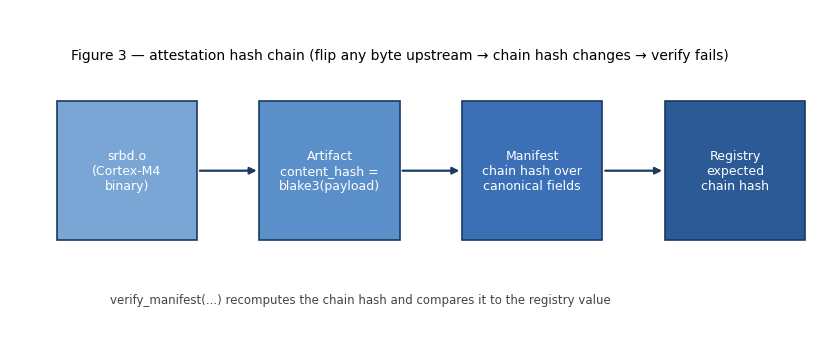

In [10]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
ax.axis("off")

boxes = [
    (0.06, "srbd.o\n(Cortex-M4\nbinary)", "#7aa6d6"),
    (0.32, "Artifact\ncontent_hash =\nblake3(payload)", "#5b8fc9"),
    (0.58, "Manifest\nchain hash over\ncanonical fields", "#3b6fb6"),
    (0.84, "Registry\nexpected\nchain hash", "#2c5a96"),
]
w, h, y = 0.18, 0.42, 0.30
for x, label, color in boxes:
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color,
                               edgecolor="#1b3a5e", lw=1.2))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center",
            color="white", fontsize=9)

for x0, x1 in [(0.06, 0.32), (0.32, 0.58), (0.58, 0.84)]:
    ax.annotate("", xy=(x1, y + h / 2), xytext=(x0 + w, y + h / 2),
                arrowprops=dict(arrowstyle="-|>", color="#1b3a5e", lw=1.6))

ax.text(0.5, 0.86,
        "Figure 3 — attestation hash chain (flip any byte upstream → chain hash changes → verify fails)",
        ha="center", va="center", fontsize=10)
ax.text(0.45, 0.12, "verify_manifest(...) recomputes the chain hash and compares it to the registry value",
        ha="center", va="center", fontsize=8.5, color="#444")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

## Limitations

This notebook is honest about its edges:

- **acados is not exercised.** We build the `OcpTemplateSpec` that an acados
  solver would consume, but the acados code generation (and the resulting
  RTI-SQP solver C) is **not run** — acados is not installed in this
  environment. Only the dynamics function was lowered, compiled, and attested
  end-to-end. The full controller binary would be the acados-generated solver
  cross-compiled the same way.
- **No on-silicon hardware-in-the-loop.** We verify the object is a valid
  `ELF32`/`ARM` Cortex-M4 binary, but we never flash it to a board, link it
  against a runtime, or run it under a real-time scheduler. Timing, stack usage,
  and FPU behaviour on real silicon are out of scope here.
- **Floating-point, not fixed-point.** We deploy float64 math compiled for the
  M4's single-precision FPU. We do not quantize to fixed-point, which some
  ultra-constrained MCUs (no FPU) would require, and which changes the numerics.
- **Two baked contacts, static points.** The deployed function bakes in fixed
  contact points. A real controller re-lowers (or parameterizes) per stance
  configuration; contact *scheduling* is Part 4's concern, not this one.
- **One signer, no crypto.** OSS attestation is hash-chain integrity only
  (`signature_status == "absent"`); cryptographic signing is not
  demonstrated here.

## Exercises

1. **Three contacts.** Extend `srbd2` to three baked contact points
   (`u ∈ ℝ⁹`), re-lower with `in_shapes=((9,), (9,))`, and confirm the
   equivalence gate still holds. How does `srbd.o`'s size change?
2. **Single precision.** Re-run `translate(..., dtype="float32")`, recompile,
   and measure the JAX↔CasADi error. Does it still clear a sensible gate? What
   gate would you set for float32?
3. **Coverage.** Add a deliberately unlowerable op (e.g. a `jnp.where` on a
   data-dependent predicate, or a `lax.while_loop`) to `srbd2` and observe how
   `translate` / the coverage table responds. Why does the MJX whole-body model
   hit exactly this wall?
4. **Tamper somewhere else.** Instead of flipping a binary byte, tamper with the
   manifest's `toolchain_versions` and re-verify against the registry. Does the
   chain still catch it? Why?
5. **Compare targets.** Cross-compile the same C for `cortex-a55`
   (`-mcpu=cortex-a55`, AArch64 toolchain) and compare object sizes and the
   `readelf` machine field.

## References

- J. A. E. Andersson, J. Gillis, G. Horn, J. B. Rawlings, M. Diehl.
  **CasADi — a software framework for nonlinear optimization and optimal
  control.** *Mathematical Programming Computation*, 11(1):1–36, 2019.
- R. Verschueren, G. Frison, D. Kouzoupis, J. Frey, N. van Duijkeren,
  A. Zanelli, B. Novoselnik, T. Albin, R. Quirynen, M. Diehl.
  **acados — a modular open-source framework for fast embedded optimal
  control.** *Mathematical Programming Computation*, 14:147–183, 2022.
- **Arm GNU Toolchain (`arm-none-eabi`).** Arm Ltd. Bare-metal Cortex-M/-A
  cross-compilation toolchain.
- D.E. Orin, A. Goswami, S.-H. Lee. **Centroidal dynamics of a humanoid
  robot.** *Autonomous Robots*, 35:161–176, 2013. (The SRBD / centroidal model
  deployed here.)

## Series wrap-up — the whole locomotion stack, end to end

Six parts, one arc: from the physics of balance to a binary on the robot.

1. **Reduced-order models & the capture point.** The single-rigid-body and
   linear-inverted-pendulum surrogates, and the capture point $\xi = c+\dot
   c/\omega$ — the smooth, tractable physics everything downstream plans on
   (because the full MJX dynamics cannot be lowered).
2. **Centroidal MPC.** Optimize contact forces over a horizon on the SRBD,
   subject to friction cones — the OCP whose template spec we built in §4.
3. **Whole-body control.** Map the centroidal plan onto the robot's real
   joints, reconciling the reduced plan with full-body kinematics and limits.
4. **Gaits & footstep planning.** Turn capture points into a *sequence* of
   steps — where to put each foot and when.
5. **Push recovery.** React to disturbances by stepping when the capture point
   leaves the support region.
6. **Embedded deploy** *(this notebook)*. Lower the reduced model to CasADi C,
   cross-compile to a real Cortex-M4 object, build the centroidal-MPC OCP spec,
   and wrap a tamper-evident attestation manifest around the binary.

The through-line: the controller is designed in JAX where autodiff and
vectorization make it cheap to build and verify, **planned on the reduced model
because that is the only part that lowers**, and shipped to the robot as attested
C. The MJX whole-body model stays on the workstation as ground truth; the smooth
reduced model is what crosses to silicon. That division — rich simulation up
top, lowerable surrogate at the bottom — is the spine of the entire Jaxterity →
Jaxility deployment story.